In [1]:
# -*- coding: utf-8 -*-
import time
import numpy as np
import torch
import torch.nn as nn
import math
from scipy.io import savemat
from scipy.linalg import lstsq,pinv
from scipy.fftpack import fftshift,fftn
from scipy.sparse import coo_matrix
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import itertools
import seaborn as sns
torch.set_default_dtype(torch.float64)

In [2]:
def set_seed(x):
    np.random.seed(x)
    torch.manual_seed(x)
    torch.cuda.manual_seed_all(x)
    torch.backends.cudnn.deterministic = True

In [3]:
##数据初始化，可以使用均匀分布，也可以使用正态分布

In [4]:
rand_mag = 1.0
def weights_init(m):
    if isinstance(m, (nn.Conv2d, nn.Linear)):
        nn.init.uniform_(m.weight, a = -rand_mag, b = rand_mag)
        nn.init.uniform_(m.bias, a = -rand_mag, b = rand_mag)
        #nn.init.normal_(m.weight, mean=0, std=1)
        #nn.init.normal_(m.bias, mean=0, std=1)

In [5]:
##RFM_rep(nn.Module)
##进行初始化与归一化
##构造单位分解函数，包括均匀单位分解

In [6]:
class RFM_rep(nn.Module):
    def __init__(self, in_features, out_features, hidden_layers, M, x_max, x_min, t_max, t_min):
        super(RFM_rep, self).__init__()
        self.in_features = in_features
        self.out_features = out_features
        self.hidden_features = M
        self.hidden_layers  = hidden_layers
        self.x_max = x_max
        self.x_min = x_min
        self.t_max = t_max
        self.t_min = t_min
        self.M = M
        self.a = torch.tensor([2.0/(x_max - x_min),2.0/(t_max - t_min)])
        self.x_0 = torch.tensor([(x_max + x_min)/2,(t_max + t_min)/2])
        self.hidden_layer = nn.Sequential(nn.Linear(self.in_features, self.hidden_features, bias=True),nn.Tanh())
        #print([x_min,x_max],[t_min,t_max])

    def forward(self,x):
#        dx = (x[:,:,:1] - self.x_min) / (self.x_max - self.x_min)
#        dt = (x[:,:,1:] - self.t_min) / (self.t_max - self.t_min)
#        
#        dx0 = dx <= -1/4
#        dx1 = (dx <= 1/4)  & (dx > -1/4)
#        dx2 = (dx <= 3/4)  & (dx > 1/4)
#        dx3 = (dx <= 5/4)  & (dx > 3/4)
#        dx4 = dx > 5/4
#        
#        dt0 = dt <= -1/4
#        dt1 = (dt <= 1/4)  & (dt > -1/4)
#        dt2 = (dt <= 3/4)  & (dt > 1/4)
#        dt3 = (dt <= 5/4)  & (dt > 3/4)
#        dt4 = dt > 5/4
#        
#        yx0 = 0.0
#        yx1 = (1 + torch.sin(2*np.pi*dx) ) / 2
#        yx2 = 1.0
#        yx3 = (1 - torch.sin(2*np.pi*(dx-1)) ) / 2
#        yx4 = 0.0
#        
#        yt0 = 0.0
#        yt1 = (1 + torch.sin(2*np.pi*dt) ) / 2
#        yt2 = 1.0
#        yt3 = (1 - torch.sin(2*np.pi*(dt-1)) ) / 2
#        yt4 = 0.0
        
        3
        y = self.a * (x - self.x_0)
        y = self.hidden_layer(y)
        
        dx = (x[:,:,:1] - (self.x_min + self.x_max)/2) / ((self.x_max - self.x_min)/2)
        dt = (x[:,:,1:] - (self.t_min + self.t_max)/2) / ((self.t_max - self.t_min)/2)
        
        dx0 = dx <= -5/4
        dx1 = (dx <= -3/4)  & (dx > -5/4)
        dx2 = (dx <= 3/4)  & (dx > -3/4)
        dx3 = (dx <= 5/4)  & (dx > 3/4)
        dx4 = dx > 5/4
        
        dt0 = dt <= -5/4
        dt1 = (dt <= -3/4)  & (dt > -5/4)
        dt2 = (dt <= 3/4)  & (dt > -3/4)
        dt3 = (dt <= 5/4)  & (dt > 3/4)
        dt4 = dt > 5/4
        
        yx0 = 0.0
        yx1 = (1 + torch.sin(2*np.pi*dx) ) / 2
        yx2 = 1.0
        yx3 = (1 - torch.sin(2*np.pi*dx) ) / 2
        yx4 = 0.0
        
        yt0 = 0.0
        yt1 = (1 + torch.sin(2*np.pi*dt) ) / 2
        yt2 = 1.0
        yt3 = (1 - torch.sin(2*np.pi*dt) ) / 2
        yt4 = 0.0
        
        #print(y.shape,dx0.shape,yx0)
        if self.x_min == 0:
            y = y*(dx0*yx0+(dx1+dx2)*yx2+dx3*yx3+dx4*yx4)
        elif self.x_max == L:
            y = y*(dx0*yx0+dx1*yx1+(dx2+dx3)*yx2+dx4*yx4)
        else:
            y = y*(dx0*yx0+dx1*yx1+dx2*yx2+dx3*yx3+dx4*yx4)
        
        if self.t_min == 0:
            y = y*(dt0*yt0+(dt1+dt2)*yt2+dt3*yt3+dt4*yt4)
        elif self.t_max == tf:
            y = y*(dt0*yt0+dt1*yt1+(dt2+dt3)*yt2+dt4*yt4)
        else:
            y = y*(dt0*yt0+dt1*yt1+dt2*yt2+dt3*yt3+dt4*yt4)
        
        return y

In [7]:
L = 1.0
tf = 1.0

A = 1.0
a = np.pi
b = 2*np.pi

B = 0.0
c = 2*np.pi
d = 4*np.pi

In [8]:
def anal_u(x,y):
    u = -A*(1.5*np.cos(a*x+2*np.pi/5) + 2*np.cos(b*x-np.pi/5))*\
         (1.5*np.cos(a*y+2*np.pi/5) + 2*np.cos(b*y-np.pi/5))\
        -B*(1.5*np.cos(c*x+2*np.pi/5) + 2*np.cos(d*x-np.pi/5))*\
         (1.5*np.cos(c*y+2*np.pi/5) + 2*np.cos(d*y-np.pi/5))
    return u

In [9]:
def anal_d2udx2_plus_d2udy2(x,y):
    f = -A*(-1.5*a*a*np.cos(a*x+2*np.pi/5) - 2*b*b*np.cos(b*x-np.pi/5))*\
         (1.5*np.cos(a*y+2*np.pi/5) + 2*np.cos(b*y-np.pi/5)) \
         -A*(1.5*np.cos(a*x+2*np.pi/5) + 2*np.cos(b*x-np.pi/5))*\
         (-1.5*a*a*np.cos(a*y+2*np.pi/5) - 2*b*b*np.cos(b*y-np.pi/5))\
        -B*(-1.5*c*c*np.cos(c*x+2*np.pi/5) - 2*d*d*np.cos(d*x-np.pi/5))*\
         (1.5*np.cos(c*y+2*np.pi/5) + 2*np.cos(d*y-np.pi/5)) \
         -B*(1.5*np.cos(c*x+2*np.pi/5) + 2*np.cos(d*x-np.pi/5))*\
         (-1.5*c*c*np.cos(c*y+2*np.pi/5) - 2*d*d*np.cos(d*y-np.pi/5))
    return f

In [10]:
vanal_u = np.vectorize(anal_u)
vanal_f = np.vectorize(anal_d2udx2_plus_d2udy2)

In [20]:
def pre_define(Nx, Ny, M, Qx, Qy, L, tf, RFM_rep, weights_init):
    models = []
    points = []

    for k in range(Nx):
        model_for_x = []
        point_for_x = []

        x_min = L / Nx * k
        x_max = L / Nx * (k + 1)
        x_divide = np.linspace(x_min, x_max, Qx + 1)

        for n in range(Ny):
            t_min = tf / Ny * n
            t_max = tf / Ny * (n + 1)

            # Create local model
            model = RFM_rep(
                in_features=2,
                out_features=1,
                hidden_layers=1,
                M=M,
                x_min=x_min,
                x_max=x_max,
                t_min=t_min,
                t_max=t_max
            )
            model.apply(weights_init)
            model = model.double().to(device)
            for param in model.parameters():
                param.requires_grad = False
            model_for_x.append(model)

            # Create grid points
            t_divide = np.linspace(t_min, t_max, Qy + 1)
            grid = np.array(list(itertools.product(x_divide, t_divide))).reshape(Qx + 1, Qy + 1, 2)
            grid_tensor = torch.tensor(grid, dtype=torch.double, requires_grad=True).to(device)
            point_for_x.append(grid_tensor)

        models.append(model_for_x)
        points.append(point_for_x)

    return models, points

In [12]:
def cal_matrix(models,points,Nx,Ny,M,Qx,Qy):
    # matrix define (Aw=b)
    A_1 = np.zeros([Nx*Ny*Qx*Qy,Nx*Ny*M]) # u_t - c*u_x = 0
    f_1 = np.zeros([Nx*Ny*Qx*Qy,1])
    
    A_2 = np.zeros([Nx*Qx,Nx*Ny*M]) # u(x,0) = h(x)
    f_2 = np.zeros([Nx*Qx,1])
    
    A_3 = np.zeros([Nx*Qx,Nx*Ny*M]) # u(x,0) = h(x)
    f_3 = np.zeros([Nx*Qx,1])
    
    A_4 = np.zeros([Ny*Qy,Nx*Ny*M]) # u(x,0) = h(x)
    f_4 = np.zeros([Ny*Qy,1])
    
    A_5 = np.zeros([Ny*Qy,Nx*Ny*M]) # u(x,0) = h(x)
    f_5 = np.zeros([Ny*Qy,1])
    
    for k in range(Nx):
        for n in range(Ny):
            print(k,n)
            # u_t - c*u_x = 0
            in_ = points[k][n].detach().numpy()
            out = models[k][n](points[k][n])
            values = out.detach().numpy()
            M_begin = k*Ny*M + n*M
            if n == 0:
                #A_2[k*Qx : k*Qx+Qx, M_begin : M_begin + M] = values[:Qx,0,:]
                f_2[k*Qx : k*Qx+Qx,:] = \
                    vanal_u(in_[:Qx,0,0],in_[:Qx,0,1]).reshape((Qx,1))
            
            # u(x,1) = ..
            if n == Ny-1:
                #A_3[k*Qx : k*Qx+Qx, M_begin : M_begin + M] = values[:Qx,-1,:]
                f_3[k*Qx : k*Qx+Qx,:] =\
                    vanal_u(in_[:Qx,-1,0],in_[:Qx,-1,1]).reshape((Qx,1))
            
            # u(0,t) = ..
            if k == 0:
                #A_4[n*Qy : n*Qy+Qy, M_begin : M_begin + M] = values[0,:Qy,:]
                f_4[n*Qy : n*Qy+Qy,:] =\
                    vanal_u(in_[0,:Qy,0],in_[0,:Qy,1]).reshape((Qy,1))
                #print(in_[0,:Qy,:])
            
            # u(1,t) = ..
            if k == Nx-1:
                #A_5[n*Qy : n*Qy+Qy, M_begin : M_begin + M] = values[-1,:Qy,:]
                f_5[n*Qy : n*Qy+Qy,:] = \
                    vanal_u(in_[-1,:Qy,0],in_[-1,:Qy,1]).reshape((Qy,1))
                #print(in_[-1,:Qy,:])
            
            f_in = in_[:Qx,:Qy,:].reshape((-1,2))
            f_1[k*Ny*Qx*Qy + n*Qx*Qy : k*Ny*Qx*Qy + n*Qx*Qy + Qx*Qy, :] = vanal_f(f_in[:,0],f_in[:,1]).reshape(-1,1)
            
            for k_ in range(Nx):
                for n_ in range(Ny):
                    # u_t - c*u_x = 0
                    out = models[k_][n_](points[k][n])
                    values = out.detach().numpy()
                    M_begin = k_*Ny*M + n_*M
                    #print(values.shape)
                    grads = []
                    grads_2_xx = []
                    grads_2_yy = []
                    for i in range(M):
                        g_1 = torch.autograd.grad(outputs=out[:,:,i], inputs=points[k][n],
                                              grad_outputs=torch.ones_like(out[:,:,i]),
                                              create_graph = True, retain_graph = True)[0]
                        grads.append(g_1.squeeze().detach().numpy())
                        
                        g_2_x = torch.autograd.grad(outputs=g_1[:,:,0], inputs=points[k][n],
                                          grad_outputs=torch.ones_like(out[:,:,i]),
                                          create_graph = True, retain_graph = True)[0]
                        g_2_y = torch.autograd.grad(outputs=g_1[:,:,1], inputs=points[k][n],
                                          grad_outputs=torch.ones_like(out[:,:,i]),
                                          create_graph = True, retain_graph = True)[0]
                        grads_2_xx.append(g_2_x[:,:,0].squeeze().detach().numpy())
                        grads_2_yy.append(g_2_y[:,:,1].squeeze().detach().numpy())
                        
                    grads = np.array(grads).swapaxes(0,3)
                    
                    #print(values.shape,grads.shape)
                    #grads = grads[:,:Qx,:Qy,:].reshape(M,-1,2)
                    grads_2_xx = np.array(grads_2_xx)
                    grads_2_xx = grads_2_xx[:,:Qx,:Qy]
                    grads_2_xx = grads_2_xx.transpose(1,2,0).reshape(-1,M)
                    grads_2_yy = np.array(grads_2_yy)
                    grads_2_yy = grads_2_yy[:,:Qx,:Qy]
                    grads_2_yy = grads_2_yy.transpose(1,2,0).reshape(-1,M)
                    
                    A_1[k*Ny*Qx*Qy + n*Qx*Qy : k*Ny*Qx*Qy + n*Qx*Qy + Qx*Qy, M_begin : M_begin + M] = grads_2_xx + grads_2_yy
                    
                    # u(x,0) = ..
                    if n == 0:
                        A_2[k*Qx : k*Qx+Qx, M_begin : M_begin + M] = values[:Qx,0,:]
                    # u(x,1) = ..
                    if n == Ny-1:
                        A_3[k*Qx : k*Qx+Qx, M_begin : M_begin + M] = values[:Qx,-1,:]
                    # u(0,t) = ..
                    if k == 0:
                        A_4[n*Qy : n*Qy+Qy, M_begin : M_begin + M] = values[0,:Qy,:]
                    # u(1,t) = ..
                    if k == Nx-1:
                        A_5[n*Qy : n*Qy+Qy, M_begin : M_begin + M] = values[-1,:Qy,:]
                    
            

    A = np.concatenate((A_1,A_2,A_3,A_4,A_5),axis=0)
    f = np.concatenate((f_1,f_2,f_3,f_4,f_5),axis=0)
    print(f.shape)
    return(A,f)

In [18]:
def test(models,Nx,Ny,M,Qx,Qy,w,plot = False):
    epsilon = []
    true_values = []
    numerical_values = []
    test_Qx = int(1000/Nx)
    test_Qy = int(1000/Ny)
    L = 1.0
    tf = 1.0
    for k in range(Nx):
        epsilon_x = []
        true_value_x = []
        numerical_value_x = []
        for n in range(Ny):
            numerical_value = None
            # forward and grad
            x_min = L/Nx * k
            x_max = L/Nx * (k+1)
            x_devide = np.linspace(x_min, x_max, test_Qx + 1)[:test_Qx]
            t_min = tf/Ny * n
            t_max = tf/Ny * (n+1)
            t_devide = np.linspace(t_min, t_max, test_Qy + 1)[:test_Qy]
            grid = np.array(list(itertools.product(x_devide,t_devide))).reshape(test_Qx,test_Qy,2)
            test_point = torch.tensor(grid,requires_grad=True)
            in_ = test_point.detach().numpy()
            true_value = vanal_u(in_[:,:,0],in_[:,:,1])
            for k_ in range(Nx):
                for n_ in range(Ny):
                        out = models[k_][n_](test_point)
                        values = out.detach().numpy()
                        if numerical_value is None:
                            numerical_value = np.dot(values, w[k_*Ny*M + n_*M : k_*Ny*M + n_*M + M,:]).reshape(test_Qx,test_Qy)
                        else:
                            numerical_value = numerical_value + np.dot(values, w[k_*Ny*M + n_*M : k_*Ny*M + n_*M + M,:]).reshape(test_Qx,test_Qy)
            e = np.abs(true_value - numerical_value)
            true_value_x.append(true_value)
            numerical_value_x.append(numerical_value)
            epsilon_x.append(e)
        epsilon_x = np.concatenate(epsilon_x, axis=1)
        epsilon.append(epsilon_x)
        true_value_x = np.concatenate(true_value_x, axis=1)
        true_values.append(true_value_x)
        numerical_value_x = np.concatenate(numerical_value_x, axis=1)
        numerical_values.append(numerical_value_x)
    epsilon = np.concatenate(epsilon, axis=0)
    true_values = np.concatenate(true_values, axis=0)
    numerical_values = np.concatenate(numerical_values, axis=0)
    e = epsilon.reshape((-1,1))
    print('********************* ERROR *********************')
    print('Nx=%s,Ny=%s,M=%s,Qx=%s,Qy=%s'%(Nx,Ny,M,Qx,Qy))
    print('L_inf=',e.max(),'L_2=',math.sqrt(np.sum(e*e)/len(e)))
    print("边值条件误差")
    print(max(epsilon[0,:]),max(epsilon[-1,:]),max(epsilon[:,0]),max(epsilon[:,-1]))
    np.save('./epsilon_psi2.npy',epsilon)
    if True:
        L,tf=1,1
        x = np.linspace(0, L, 1001)[:1000]
        y = np.linspace(0, tf, 1001)[:1000]
        x,y = np.meshgrid(x,y)
        plt.figure(figsize=[12, 10])
        plt.axis('equal')
        plt.xlim([0,1])
        plt.ylim([0,1])
        plt.tick_params(labelsize=15)
        font2 = {
        'weight' : 'normal',
        'size'   : 20,
        }
        plt.xlabel('x',font2)
        plt.ylabel('y',font2)
        plt.pcolor(x,y,epsilon.T, cmap='jet')
        cbar = plt.colorbar()
        cbar.ax.tick_params(labelsize=15)
        cbar.ax.yaxis.get_offset_text().set_fontsize(15)
        cbar.update_ticks()
        plt.savefig('./Poisson2d_psi2.pdf')
        #sns.heatmap(epsilon.T, cmap="YlGnBu").invert_yaxis()
        #plt.savefig('D:/result/3-1-1/Poisson2d_Nx=%s_Ny=%s_M=%s_Q=%s.pdf'%(Nx,Ny,M,Qx), dpi=300)
    return(e.max(),math.sqrt(np.sum(e*e)/len(e)))


In [16]:
def main(Nx,Ny,M,Qx,Qy,plot = False,moore = False):
    # prepare models and collocation pointss
    models,points = pre_define(Nx,Ny,M,Qx,Qy)
    
    # matrix define (Aw=b)
    A,f = cal_matrix(models,points,Nx,Ny,M,Qx,Qy)
    
    max_value = 10.0
    for i in range(len(A)):
        if np.abs(A[i,:].max())==0:
            print("error line : ",i)
            continue
        ratio = max_value/np.abs(A[i,:]).max()
        A[i,:] = A[i,:]*ratio
        f[i] = f[i]*ratio
    sparse_matrix = coo_matrix(A)
    # solve
    if moore:
        inv_coeff_mat = pinv(A)  # moore-penrose inverse, shape: (n_units,n_colloc+2)
        w = np.matmul(inv_coeff_mat, f)
    else:
        w = lstsq(A,f)[0]
    savemat("./2D_Poisson_psi-b_Mp=4_Jn=1600_Q=6400.mat",{'matrix': A, 'sparse_matrix': sparse_matrix, \
                                                          'vector': f, 'solution': w})
    # test
    return(test(models,Nx,Ny,M,Qx,Qy,w,plot))

In [1]:
if __name__ == '__main__':
    set_seed(100)
    result = []
    main(2,2,1600,40,40,True)

NameError: name 'set_seed' is not defined

In [ ]:
def test(models,M_p,J_n,Q,w,plot = False):
    epsilon = []
    true_values = []
    numerical_values = []
    test_Q = 2*Q
    for n in range(M_p):
        points = torch.tensor(np.linspace((X_max-X_min)/M_p * n + X_min, (X_max-X_min)/M_p * (n+1) + X_min, test_Q+1),requires_grad=False).reshape([-1,1])
        out = models[n](points)
        values = out.detach().numpy()
        true_value = vanal_u(points.numpy()).reshape([-1,1])
        numerical_value = np.dot(values, w[n*J_n:(n+1)*J_n,:])
        true_values.extend(true_value)
        numerical_values.extend(numerical_value)
        epsilon.extend(true_value - numerical_value)
    true_values = np.array(true_values)
    numerical_values = np.array(numerical_values)
    epsilon = np.array(epsilon)
    epsilon = np.maximum(epsilon, -epsilon)
    #print('R_m=%s,M_p=%s,J_n=%s,Q=%s'%(R_m,M_p,J_n,Q))
    #print('L_infty error =',epsilon.max(),', L_2 error =',math.sqrt(8*sum(epsilon*epsilon)/len(epsilon)))
    x = [((X_max - X_min)/M_p)*i / test_Q  for i in range(M_p*(test_Q+1))]
    return(math.sqrt((X_max-X_min)*sum(epsilon*epsilon)/len(epsilon)))

def main(M_p, J_n, Q, lamb):
    # prepare collocation points
    points = []
    for n in range(M_p):
        x_min = (X_max-X_min)/M_p * n + X_min
        x_max = (X_max-X_min)/M_p * (n+1) + X_min
        points.append(np.linspace(x_min, x_max, Q+1).reshape([-1,1]))
    
    # prepare models
    models = pre_define(M_p,J_n)
    
    # matrix define (Au=f)
    A,f = assemble_matrix(models, points, M_p, J_n, Q, lamb)
    #print('***********************')
    #print('Matrix shape: N=%s,M=%s'%(A.shape))
    # rescaling
    c = 100.0
    for i in range(len(A)):
        ratio = c/A[i,:].max()
        A[i,:] = A[i,:]*ratio
        f[i] = f[i]*ratio
    
    # solve
    w = lstsq(A,f)[0]
    
    # test
    return(A.shape[0],test(models,M_p,J_n,Q,w))

def error_plot_semi_log(Error):
    import matplotlib.pyplot as plt
    plt.figure(figsize=[7, 5])
    plt.tick_params(labelsize=10)
    font2 = {
    'weight' : 'normal',
    'size'   : 22,
    }
    plt.xlabel('Degrees of freedom',font2)
    plt.ylabel('$L_2$ absolute errors',font2)
    plt.yscale('log')
    plt.plot(Error[:,0], Error[:,1], \
             color='black', lw=1.5, ls='-', clip_on=False,\
             marker='o', markersize=10, \
             markerfacecolor='none',\
             markeredgecolor='black',markeredgewidth=1.5)
    plt.title("Spectral accuracy of RFM")
    plt.show()

if __name__ == '__main__':
    lamb = 4
    R_m = 3
    M_p = 4 # the number of PoU regions
    J_n = 50 # the number of basis functions per PoU region
    
    Error = np.zeros([8,2])
    for i in range(8):
        Q = int(10 * (i+1)) # the number of collocation pointss per PoU region
        m = []
        for o in range(40): # 40 experiments for mean
            N, error = main(M_p,J_n,Q,lamb)
            m.append(error)
        Error[i,0] = N
        Error[i,1] = np.array(m).mean()
    error_plot_semi_log(Error)

0 0
0 1
1 0
1 1
(6720, 1)
********************* ERROR *********************
Nx=2,Ny=2,M=1600,Qx=40,Qy=40
L_inf= 5.589928520066678e-11 L_2= 1.0722982045917772e-11
边值条件误差
1.738165167353145e-11 2.0271340162025808e-11 1.738431620879055e-11 2.0065948902470154e-11


C:\Users\黄南樵\AppData\Local\Temp\ipykernel_15216\3232159535.py:351: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  print('L_inf=',e.max(),'L_2=',math.sqrt(sum(e*e)/len(e)))
C:\Users\黄南樵\AppData\Local\Temp\ipykernel_15216\3232159535.py:379: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  return(e.max(),math.sqrt(sum(e*e)/len(e)))


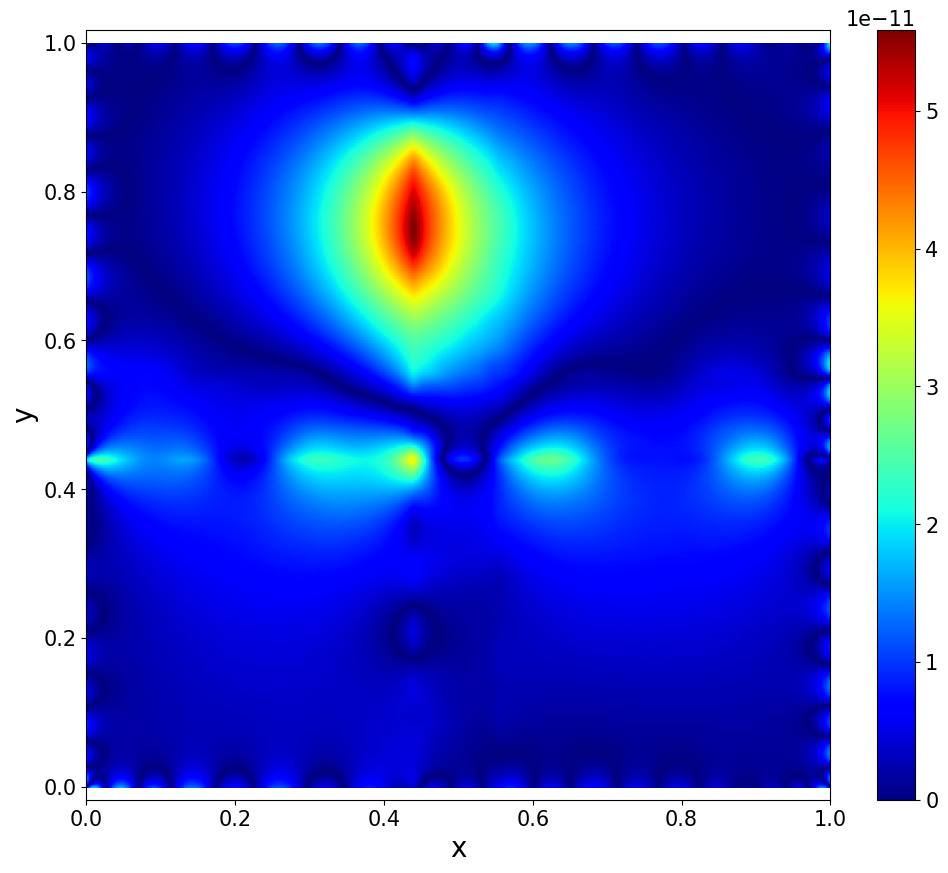

In [2]:
# -*- coding: utf-8 -*-

import time
import numpy as np
import torch
import torch.nn as nn
import math
from scipy.io import savemat
from scipy.linalg import lstsq,pinv
from scipy.fftpack import fftshift,fftn
from scipy.sparse import coo_matrix
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import itertools
import seaborn as sns
torch.set_default_dtype(torch.float64)

def set_seed(x):
    np.random.seed(x)
    torch.manual_seed(x)
    torch.cuda.manual_seed_all(x)
    torch.backends.cudnn.deterministic = True


rand_mag = 1.0
def weights_init(m):
    if isinstance(m, (nn.Conv2d, nn.Linear)):
        nn.init.uniform_(m.weight, a = -rand_mag, b = rand_mag)
        nn.init.uniform_(m.bias, a = -rand_mag, b = rand_mag)
        #nn.init.normal_(m.weight, mean=0, std=1)
        #nn.init.normal_(m.bias, mean=0, std=1)


class RFM_rep(nn.Module):
    def __init__(self, in_features, out_features, hidden_layers, M, x_max, x_min, t_max, t_min):
        super(RFM_rep, self).__init__()
        self.in_features = in_features
        self.out_features = out_features
        self.hidden_features = M
        self.hidden_layers  = hidden_layers
        self.x_max = x_max
        self.x_min = x_min
        self.t_max = t_max
        self.t_min = t_min
        self.M = M
        self.a = torch.tensor([2.0/(x_max - x_min),2.0/(t_max - t_min)])
        self.x_0 = torch.tensor([(x_max + x_min)/2,(t_max + t_min)/2])
        self.hidden_layer = nn.Sequential(nn.Linear(self.in_features, self.hidden_features, bias=True),nn.Tanh())
        #print([x_min,x_max],[t_min,t_max])

    def forward(self,x):
#        dx = (x[:,:,:1] - self.x_min) / (self.x_max - self.x_min)
#        dt = (x[:,:,1:] - self.t_min) / (self.t_max - self.t_min)
#        
#        dx0 = dx <= -1/4
#        dx1 = (dx <= 1/4)  & (dx > -1/4)
#        dx2 = (dx <= 3/4)  & (dx > 1/4)
#        dx3 = (dx <= 5/4)  & (dx > 3/4)
#        dx4 = dx > 5/4
#        
#        dt0 = dt <= -1/4
#        dt1 = (dt <= 1/4)  & (dt > -1/4)
#        dt2 = (dt <= 3/4)  & (dt > 1/4)
#        dt3 = (dt <= 5/4)  & (dt > 3/4)
#        dt4 = dt > 5/4
#        
#        yx0 = 0.0
#        yx1 = (1 + torch.sin(2*np.pi*dx) ) / 2
#        yx2 = 1.0
#        yx3 = (1 - torch.sin(2*np.pi*(dx-1)) ) / 2
#        yx4 = 0.0
#        
#        yt0 = 0.0
#        yt1 = (1 + torch.sin(2*np.pi*dt) ) / 2
#        yt2 = 1.0
#        yt3 = (1 - torch.sin(2*np.pi*(dt-1)) ) / 2
#        yt4 = 0.0
        
        
        y = self.a * (x - self.x_0)
        y = self.hidden_layer(y)
        
        dx = (x[:,:,:1] - (self.x_min + self.x_max)/2) / ((self.x_max - self.x_min)/2)
        dt = (x[:,:,1:] - (self.t_min + self.t_max)/2) / ((self.t_max - self.t_min)/2)
        
        dx0 = dx <= -5/4
        dx1 = (dx <= -3/4)  & (dx > -5/4)
        dx2 = (dx <= 3/4)  & (dx > -3/4)
        dx3 = (dx <= 5/4)  & (dx > 3/4)
        dx4 = dx > 5/4
        
        dt0 = dt <= -5/4
        dt1 = (dt <= -3/4)  & (dt > -5/4)
        dt2 = (dt <= 3/4)  & (dt > -3/4)
        dt3 = (dt <= 5/4)  & (dt > 3/4)
        dt4 = dt > 5/4
        
        yx0 = 0.0
        yx1 = (1 + torch.sin(2*np.pi*dx) ) / 2
        yx2 = 1.0
        yx3 = (1 - torch.sin(2*np.pi*dx) ) / 2
        yx4 = 0.0
        
        yt0 = 0.0
        yt1 = (1 + torch.sin(2*np.pi*dt) ) / 2
        yt2 = 1.0
        yt3 = (1 - torch.sin(2*np.pi*dt) ) / 2
        yt4 = 0.0
        
        #print(y.shape,dx0.shape,yx0)
        if self.x_min == 0:
            y = y*(dx0*yx0+(dx1+dx2)*yx2+dx3*yx3+dx4*yx4)
        elif self.x_max == L:
            y = y*(dx0*yx0+dx1*yx1+(dx2+dx3)*yx2+dx4*yx4)
        else:
            y = y*(dx0*yx0+dx1*yx1+dx2*yx2+dx3*yx3+dx4*yx4)
        
        if self.t_min == 0:
            y = y*(dt0*yt0+(dt1+dt2)*yt2+dt3*yt3+dt4*yt4)
        elif self.t_max == tf:
            y = y*(dt0*yt0+dt1*yt1+(dt2+dt3)*yt2+dt4*yt4)
        else:
            y = y*(dt0*yt0+dt1*yt1+dt2*yt2+dt3*yt3+dt4*yt4)
        
        return y


L = 1.0
tf = 1.0

A = 1.0
a = np.pi
b = 2*np.pi

B = 0.0
c = 2*np.pi
d = 4*np.pi

def anal_u(x,y):
    u = -A*(1.5*np.cos(a*x+2*np.pi/5) + 2*np.cos(b*x-np.pi/5))*\
         (1.5*np.cos(a*y+2*np.pi/5) + 2*np.cos(b*y-np.pi/5))\
        -B*(1.5*np.cos(c*x+2*np.pi/5) + 2*np.cos(d*x-np.pi/5))*\
         (1.5*np.cos(c*y+2*np.pi/5) + 2*np.cos(d*y-np.pi/5))
    return u

def anal_d2udx2_plus_d2udy2(x,y):
    f = -A*(-1.5*a*a*np.cos(a*x+2*np.pi/5) - 2*b*b*np.cos(b*x-np.pi/5))*\
         (1.5*np.cos(a*y+2*np.pi/5) + 2*np.cos(b*y-np.pi/5)) \
         -A*(1.5*np.cos(a*x+2*np.pi/5) + 2*np.cos(b*x-np.pi/5))*\
         (-1.5*a*a*np.cos(a*y+2*np.pi/5) - 2*b*b*np.cos(b*y-np.pi/5))\
        -B*(-1.5*c*c*np.cos(c*x+2*np.pi/5) - 2*d*d*np.cos(d*x-np.pi/5))*\
         (1.5*np.cos(c*y+2*np.pi/5) + 2*np.cos(d*y-np.pi/5)) \
         -B*(1.5*np.cos(c*x+2*np.pi/5) + 2*np.cos(d*x-np.pi/5))*\
         (-1.5*c*c*np.cos(c*y+2*np.pi/5) - 2*d*d*np.cos(d*y-np.pi/5))
    return f


vanal_u = np.vectorize(anal_u)
vanal_f = np.vectorize(anal_d2udx2_plus_d2udy2)



def pre_define(Nx,Ny,M,Qx,Qy):
    models = []
    points = []
    for k in range(Nx):
        model_for_x = []
        point_for_x = []
        x_min = L/Nx * k
        x_max = L/Nx * (k+1)
        x_devide = np.linspace(x_min, x_max, Qx + 1)
        for n in range(Ny):
            t_min = tf/Ny * n
            t_max = tf/Ny * (n+1)
            model = RFM_rep(in_features = 2, out_features = 1, hidden_layers = 1, M = M, x_min = x_min, 
                              x_max = x_max, t_min = t_min, t_max = t_max)
            model = model.apply(weights_init)
            model = model.double()
            for param in model.parameters():
                param.requires_grad = False
            model_for_x.append(model)
            t_devide = np.linspace(t_min, t_max, Qy + 1)
            grid = np.array(list(itertools.product(x_devide,t_devide))).reshape(Qx+1,Qy+1,2)
            point_for_x.append(torch.tensor(grid,requires_grad=True))
        models.append(model_for_x)
        points.append(point_for_x)
    return(models,points)


def cal_matrix(models,points,Nx,Ny,M,Qx,Qy):
    # matrix define (Aw=b)
    A_1 = np.zeros([Nx*Ny*Qx*Qy,Nx*Ny*M]) # u_t - c*u_x = 0
    f_1 = np.zeros([Nx*Ny*Qx*Qy,1])
    
    A_2 = np.zeros([Nx*Qx,Nx*Ny*M]) # u(x,0) = h(x)
    f_2 = np.zeros([Nx*Qx,1])
    
    A_3 = np.zeros([Nx*Qx,Nx*Ny*M]) # u(x,0) = h(x)
    f_3 = np.zeros([Nx*Qx,1])
    
    A_4 = np.zeros([Ny*Qy,Nx*Ny*M]) # u(x,0) = h(x)
    f_4 = np.zeros([Ny*Qy,1])
    
    A_5 = np.zeros([Ny*Qy,Nx*Ny*M]) # u(x,0) = h(x)
    f_5 = np.zeros([Ny*Qy,1])
    
    for k in range(Nx):
        for n in range(Ny):
            print(k,n)
            # u_t - c*u_x = 0
            in_ = points[k][n].detach().numpy()
            out = models[k][n](points[k][n])
            values = out.detach().numpy()
            M_begin = k*Ny*M + n*M
            if n == 0:
                #A_2[k*Qx : k*Qx+Qx, M_begin : M_begin + M] = values[:Qx,0,:]
                f_2[k*Qx : k*Qx+Qx,:] = \
                    vanal_u(in_[:Qx,0,0],in_[:Qx,0,1]).reshape((Qx,1))
            
            # u(x,1) = ..
            if n == Ny-1:
                #A_3[k*Qx : k*Qx+Qx, M_begin : M_begin + M] = values[:Qx,-1,:]
                f_3[k*Qx : k*Qx+Qx,:] =\
                    vanal_u(in_[:Qx,-1,0],in_[:Qx,-1,1]).reshape((Qx,1))
            
            # u(0,t) = ..
            if k == 0:
                #A_4[n*Qy : n*Qy+Qy, M_begin : M_begin + M] = values[0,:Qy,:]
                f_4[n*Qy : n*Qy+Qy,:] =\
                    vanal_u(in_[0,:Qy,0],in_[0,:Qy,1]).reshape((Qy,1))
                #print(in_[0,:Qy,:])
            
            # u(1,t) = ..
            if k == Nx-1:
                #A_5[n*Qy : n*Qy+Qy, M_begin : M_begin + M] = values[-1,:Qy,:]
                f_5[n*Qy : n*Qy+Qy,:] = \
                    vanal_u(in_[-1,:Qy,0],in_[-1,:Qy,1]).reshape((Qy,1))
                #print(in_[-1,:Qy,:])
            
            f_in = in_[:Qx,:Qy,:].reshape((-1,2))
            f_1[k*Ny*Qx*Qy + n*Qx*Qy : k*Ny*Qx*Qy + n*Qx*Qy + Qx*Qy, :] = vanal_f(f_in[:,0],f_in[:,1]).reshape(-1,1)
            
            for k_ in range(Nx):
                for n_ in range(Ny):
                    # u_t - c*u_x = 0
                    out = models[k_][n_](points[k][n])
                    values = out.detach().numpy()
                    M_begin = k_*Ny*M + n_*M
                    #print(values.shape)
                    grads = []
                    grads_2_xx = []
                    grads_2_yy = []
                    for i in range(M):
                        g_1 = torch.autograd.grad(outputs=out[:,:,i], inputs=points[k][n],
                                              grad_outputs=torch.ones_like(out[:,:,i]),
                                              create_graph = True, retain_graph = True)[0]
                        grads.append(g_1.squeeze().detach().numpy())
                        
                        g_2_x = torch.autograd.grad(outputs=g_1[:,:,0], inputs=points[k][n],
                                          grad_outputs=torch.ones_like(out[:,:,i]),
                                          create_graph = True, retain_graph = True)[0]
                        g_2_y = torch.autograd.grad(outputs=g_1[:,:,1], inputs=points[k][n],
                                          grad_outputs=torch.ones_like(out[:,:,i]),
                                          create_graph = True, retain_graph = True)[0]
                        grads_2_xx.append(g_2_x[:,:,0].squeeze().detach().numpy())
                        grads_2_yy.append(g_2_y[:,:,1].squeeze().detach().numpy())
                        
                    grads = np.array(grads).swapaxes(0,3)
                    
                    #print(values.shape,grads.shape)
                    #grads = grads[:,:Qx,:Qy,:].reshape(M,-1,2)
                    grads_2_xx = np.array(grads_2_xx)
                    grads_2_xx = grads_2_xx[:,:Qx,:Qy]
                    grads_2_xx = grads_2_xx.transpose(1,2,0).reshape(-1,M)
                    grads_2_yy = np.array(grads_2_yy)
                    grads_2_yy = grads_2_yy[:,:Qx,:Qy]
                    grads_2_yy = grads_2_yy.transpose(1,2,0).reshape(-1,M)
                    
                    A_1[k*Ny*Qx*Qy + n*Qx*Qy : k*Ny*Qx*Qy + n*Qx*Qy + Qx*Qy, M_begin : M_begin + M] = grads_2_xx + grads_2_yy
                    
                    # u(x,0) = ..
                    if n == 0:
                        A_2[k*Qx : k*Qx+Qx, M_begin : M_begin + M] = values[:Qx,0,:]
                    # u(x,1) = ..
                    if n == Ny-1:
                        A_3[k*Qx : k*Qx+Qx, M_begin : M_begin + M] = values[:Qx,-1,:]
                    # u(0,t) = ..
                    if k == 0:
                        A_4[n*Qy : n*Qy+Qy, M_begin : M_begin + M] = values[0,:Qy,:]
                    # u(1,t) = ..
                    if k == Nx-1:
                        A_5[n*Qy : n*Qy+Qy, M_begin : M_begin + M] = values[-1,:Qy,:]
                    
            

    A = np.concatenate((A_1,A_2,A_3,A_4,A_5),axis=0)
    f = np.concatenate((f_1,f_2,f_3,f_4,f_5),axis=0)
    print(f.shape)
    return(A,f)


def test(models,Nx,Ny,M,Qx,Qy,w,plot = False):
    epsilon = []
    true_values = []
    numerical_values = []
    test_Qx = int(1000/Nx)
    test_Qy = int(1000/Ny)
    L = 1.0
    tf = 1.0
    for k in range(Nx):
        epsilon_x = []
        true_value_x = []
        numerical_value_x = []
        for n in range(Ny):
            numerical_value = None
            # forward and grad
            x_min = L/Nx * k
            x_max = L/Nx * (k+1)
            x_devide = np.linspace(x_min, x_max, test_Qx + 1)[:test_Qx]
            t_min = tf/Ny * n
            t_max = tf/Ny * (n+1)
            t_devide = np.linspace(t_min, t_max, test_Qy + 1)[:test_Qy]
            grid = np.array(list(itertools.product(x_devide,t_devide))).reshape(test_Qx,test_Qy,2)
            test_point = torch.tensor(grid,requires_grad=True)
            in_ = test_point.detach().numpy()
            true_value = vanal_u(in_[:,:,0],in_[:,:,1])
            for k_ in range(Nx):
                for n_ in range(Ny):
                        out = models[k_][n_](test_point)
                        values = out.detach().numpy()
                        if numerical_value is None:
                            numerical_value = np.dot(values, w[k_*Ny*M + n_*M : k_*Ny*M + n_*M + M,:]).reshape(test_Qx,test_Qy)
                        else:
                            numerical_value = numerical_value + np.dot(values, w[k_*Ny*M + n_*M : k_*Ny*M + n_*M + M,:]).reshape(test_Qx,test_Qy)
            e = np.abs(true_value - numerical_value)
            true_value_x.append(true_value)
            numerical_value_x.append(numerical_value)
            epsilon_x.append(e)
        epsilon_x = np.concatenate(epsilon_x, axis=1)
        epsilon.append(epsilon_x)
        true_value_x = np.concatenate(true_value_x, axis=1)
        true_values.append(true_value_x)
        numerical_value_x = np.concatenate(numerical_value_x, axis=1)
        numerical_values.append(numerical_value_x)
    epsilon = np.concatenate(epsilon, axis=0)
    true_values = np.concatenate(true_values, axis=0)
    numerical_values = np.concatenate(numerical_values, axis=0)
    e = epsilon.reshape((-1,1))
    print('********************* ERROR *********************')
    print('Nx=%s,Ny=%s,M=%s,Qx=%s,Qy=%s'%(Nx,Ny,M,Qx,Qy))
    print('L_inf=',e.max(),'L_2=',math.sqrt(sum(e*e)/len(e)))
    print("边值条件误差")
    print(max(epsilon[0,:]),max(epsilon[-1,:]),max(epsilon[:,0]),max(epsilon[:,-1]))
    np.save('./epsilon_psi2.npy',epsilon)
    if True:
        L,tf=1,1
        x = np.linspace(0, L, 1001)[:1000]
        y = np.linspace(0, tf, 1001)[:1000]
        x,y = np.meshgrid(x,y)
        plt.figure(figsize=[12, 10])
        plt.axis('equal')
        plt.xlim([0,1])
        plt.ylim([0,1])
        plt.tick_params(labelsize=15)
        font2 = {
        'weight' : 'normal',
        'size'   : 20,
        }
        plt.xlabel('x',font2)
        plt.ylabel('y',font2)
        plt.pcolor(x,y,epsilon.T, cmap='jet')
        cbar = plt.colorbar()
        cbar.ax.tick_params(labelsize=15)
        cbar.ax.yaxis.get_offset_text().set_fontsize(15)
        cbar.update_ticks()
        plt.savefig('./Poisson2d_psi2.pdf')
        #sns.heatmap(epsilon.T, cmap="YlGnBu").invert_yaxis()
        #plt.savefig('D:/result/3-1-1/Poisson2d_Nx=%s_Ny=%s_M=%s_Q=%s.pdf'%(Nx,Ny,M,Qx), dpi=300)
    return(e.max(),math.sqrt(sum(e*e)/len(e)))


def main(Nx,Ny,M,Qx,Qy,plot = False,moore = False):
    # prepare models and collocation pointss
    models,points = pre_define(Nx,Ny,M,Qx,Qy)
    
    # matrix define (Aw=b)
    A,f = cal_matrix(models,points,Nx,Ny,M,Qx,Qy)
    
    max_value = 10.0
    for i in range(len(A)):
        if np.abs(A[i,:].max())==0:
            print("error line : ",i)
            continue
        ratio = max_value/np.abs(A[i,:]).max()
        A[i,:] = A[i,:]*ratio
        f[i] = f[i]*ratio
    sparse_matrix = coo_matrix(A)
    # solve
    if moore:
        inv_coeff_mat = pinv(A)  # moore-penrose inverse, shape: (n_units,n_colloc+2)
        w = np.matmul(inv_coeff_mat, f)
    else:
        w = lstsq(A,f)[0]
    savemat("./2D_Poisson_psi-b_Mp=4_Jn=1600_Q=6400.mat",{'matrix': A, 'sparse_matrix': sparse_matrix, \
                                                          'vector': f, 'solution': w})
    # test
    return(test(models,Nx,Ny,M,Qx,Qy,w,plot))



if __name__ == '__main__':
    set_seed(100)
    result = []
    main(2,2,1600,40,40,True)